In [1]:
from simulation import *
alpha = 0.30
beta = 0.01
param = "temp"

In [2]:
final_report = run_simulation_ts_energy(
    alpha=alpha, 
    beta=beta, 
    param=param, 
    mode='zone'
)

if final_report is not None and not final_report.empty:
    print(final_report.to_string(index=False))
else:
    print("Simulation completed: No samples met the target confidence threshold.")

 Sample_ID  Time_Seconds_End  Zone  Median_Val  Count  Binomial_%  Hoeffding_%
         1            1530.0     9      36.992    199   99.999999    99.999964
         1            1530.0    10      36.894    110   99.998685    99.970256
         1            1530.0    20      36.891    273  100.000000   100.000000
         1            1530.0     3      36.910    177   99.999996    99.999812
         1            1530.0     2      36.978    187   99.999998    99.999911
         1            1530.0     1      36.984    478  100.000000   100.000000
         1            1530.0     4      37.005    337  100.000000   100.000000
         1            1530.0     6      37.009     71   99.965889    99.495500
         1            1530.0     7      36.987     66   99.942502    99.211166
         1            1530.0     8      36.780     84   99.987900    99.793646
         1            1530.0     5      37.008     42   99.517155    95.284985
         1            1530.0    14      37.457     1

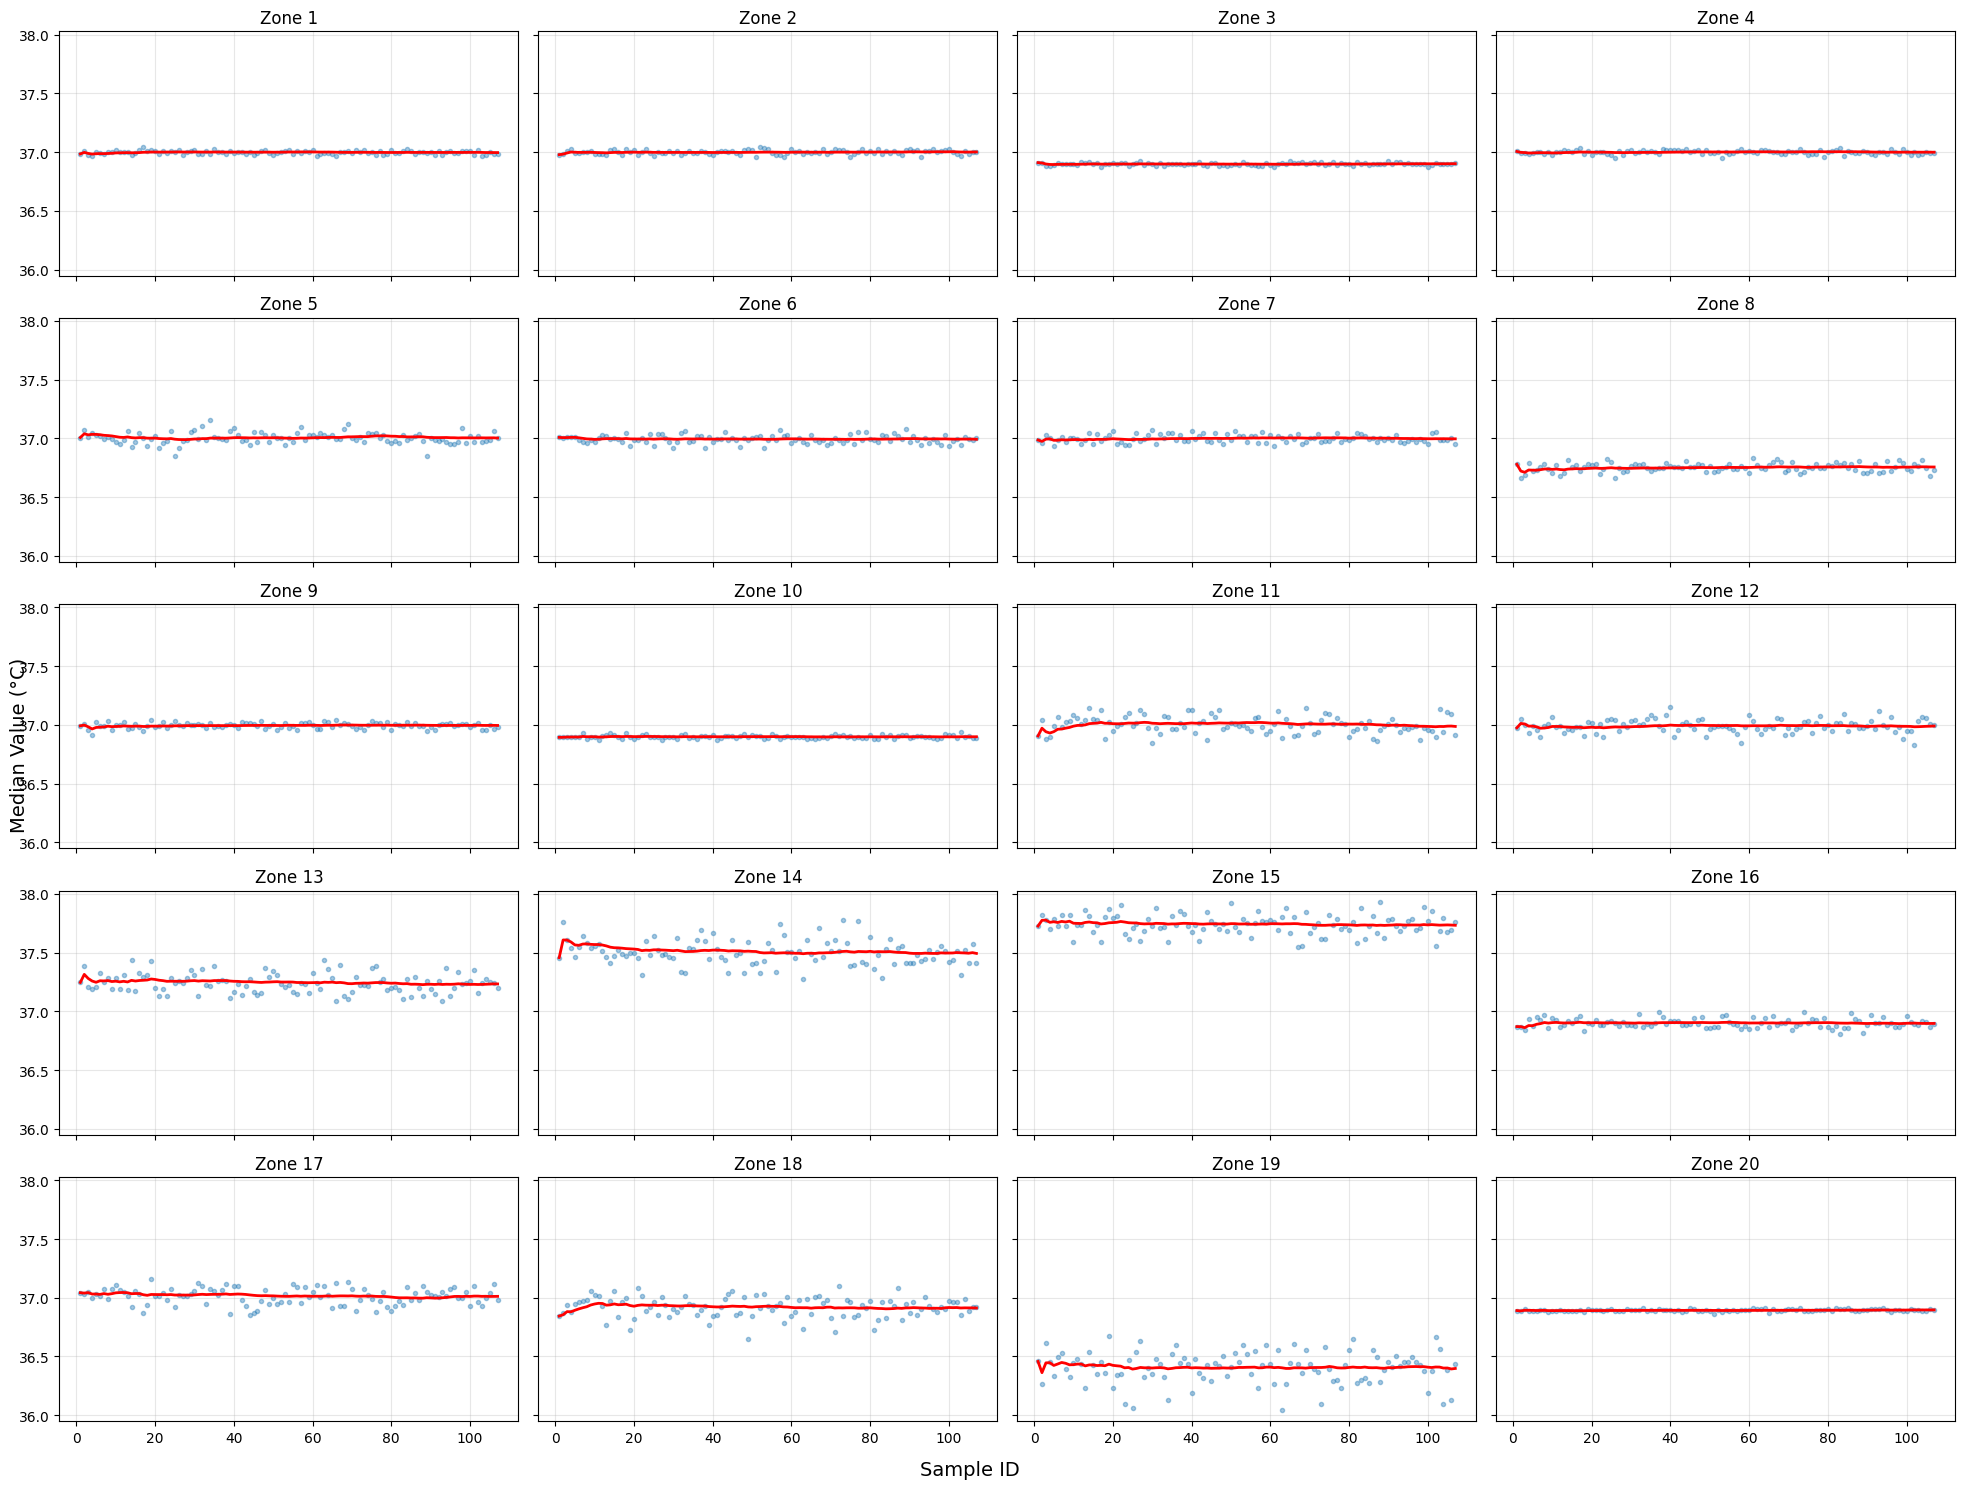

In [3]:
import matplotlib.pyplot as plt

# Get a sorted list of unique zones to ensure they plot in order (1 to 20)
zones = sorted(final_report['Zone'].dropna().unique())

# Create a 5x4 grid of subplots. 
# figsize=(20, 15) gives a nice widescreen aspect ratio.
fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(20, 15), sharex=True, sharey=True)

# Flatten the 5x4 matrix into a 1D list of 20 axes so we can loop over it easily
axes = axes.flatten()

for i, zone in enumerate(zones):
    ax = axes[i]
    zone_data = final_report[final_report['Zone'] == zone].copy()
    
    # 1. Plot raw data
    ax.plot(zone_data['Sample_ID'], zone_data['Median_Val'], 
            marker='o', linestyle='', markersize=3, alpha=0.4, 
            color='#1f77b4', label='Raw Median')
    
    # 2. Calculate and plot the 50-sample rolling average
    zone_data['Rolling_Mean'] = zone_data['Median_Val'].rolling(window=50, min_periods=1).mean()
    ax.plot(zone_data['Sample_ID'], zone_data['Rolling_Mean'], 
            color='red', linewidth=2, label='50-Sample Trend')

    ax.set_title(f'Zone {zone}')
    ax.grid(True, alpha=0.3)

# Add shared X and Y labels for the entire figure
fig.supxlabel('Sample ID', fontsize=14)
fig.supylabel('Median Value (°C)', fontsize=14)

# Adjust layout to prevent overlapping titles/labels
fig.tight_layout()
plt.show()

In [4]:
final_report_long = run_simulation_ts_energy(
    alpha=alpha, 
    beta=beta, 
    param=param, 
    mode='long'
)

if final_report_long is not None and not final_report_long.empty:
    print(final_report_long.to_string(index=False))
else:
    print("Simulation completed: No samples met the target confidence threshold.")

 Sample_ID  Time_Seconds_End  Selected_Vessel  Median_Val  Count  Binomial_%  Hoeffding_%
         1            6025.0             15.0      37.004     77   99.979708    99.677346
         1            6025.0             75.0      36.897     60   99.902767    98.766583
         1            6025.0             82.0      36.899     97   99.996351    99.927280
         1            6025.0             89.0      36.895    149   99.999955    99.998489
         1            6025.0             92.0      36.882    133   99.999827    99.995024
         1            6025.0             58.0      36.901    536  100.000000   100.000000
         1            6025.0             57.0      36.880    120   99.999436    99.985879
         1            6025.0             61.0      36.996    436  100.000000   100.000000
         1            6025.0             94.0      36.978    334  100.000000   100.000000
         1            6025.0              2.0      36.998   1936  100.000000   100.000000
         1

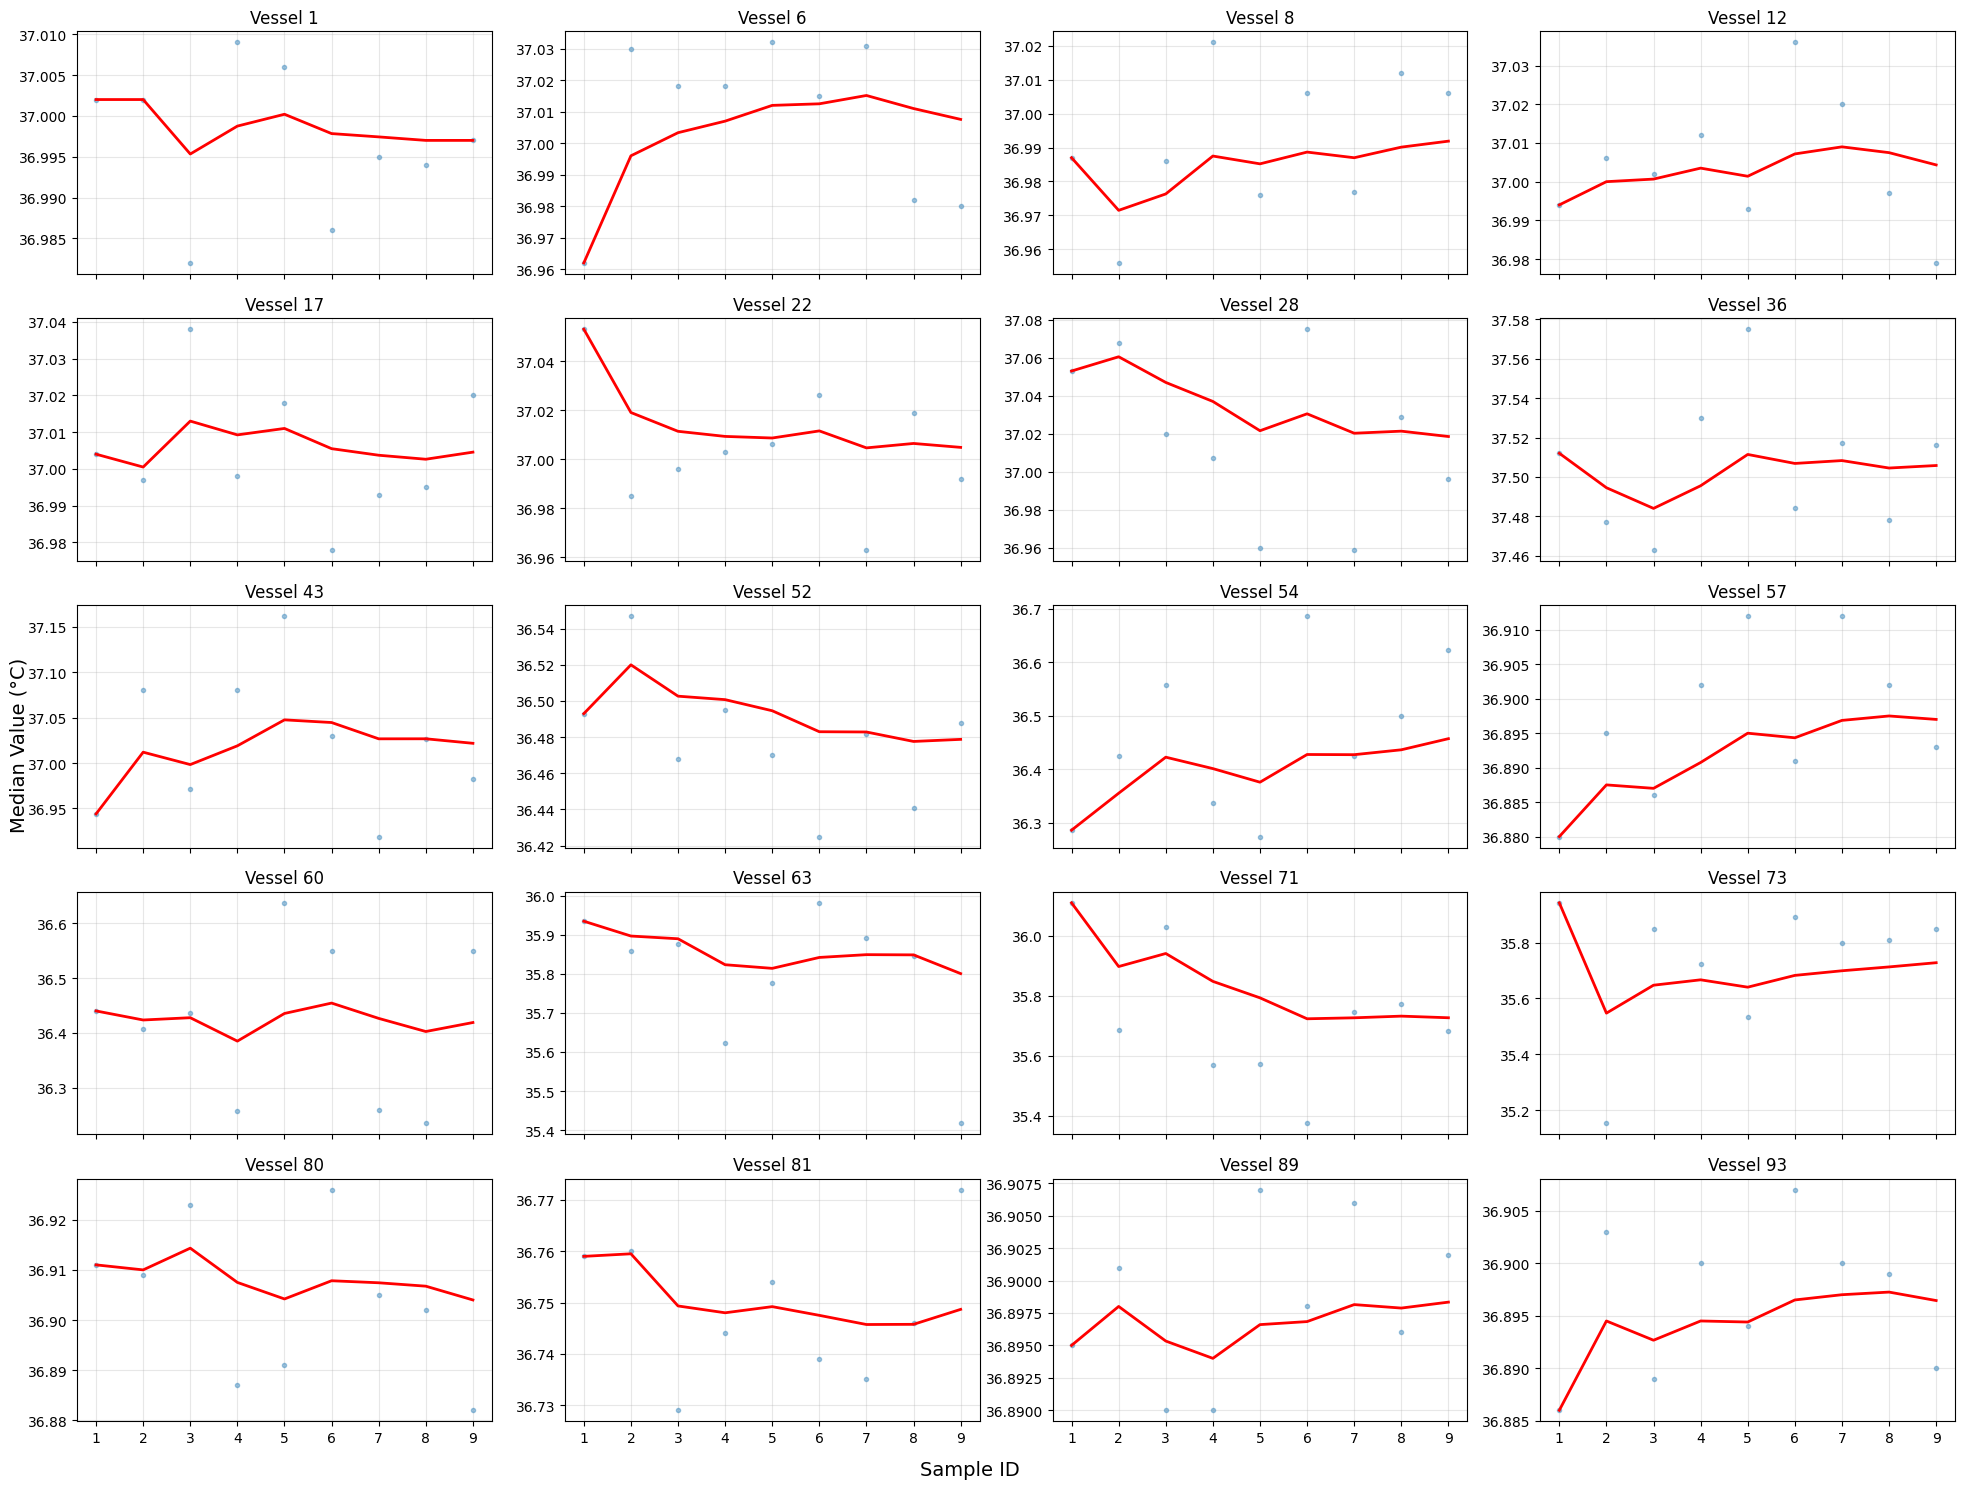

In [5]:
import matplotlib.pyplot as plt
import random

# 1. Get all unique vessels from the long simulation data
all_vessels = final_report_long['Selected_Vessel'].dropna().unique()

# Ensure we actually have at least 20 vessels to sample from
if len(all_vessels) < 20:
    print(f"Only found {len(all_vessels)} vessels. Plotting all of them.")
    selected_vessels = sorted(list(all_vessels))
else:
    # 2. Randomly select exactly 20 unique vessels and sort them for neatness
    selected_vessels = sorted(random.sample(list(all_vessels), 20))

# 3. Create the 5x4 grid
fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(20, 15), sharex=True)
axes = axes.flatten()

# 4. Loop through our 20 randomly selected vessels
for i, vessel in enumerate(selected_vessels):
    # Make sure we don't go out of bounds if there were fewer than 20 vessels total
    if i >= len(axes):
        break
        
    ax = axes[i]
    vessel_data = final_report_long[final_report_long['Selected_Vessel'] == vessel].copy()
    
    # Plot raw data dots
    ax.plot(vessel_data['Sample_ID'], vessel_data['Median_Val'], 
            marker='o', linestyle='', markersize=3, alpha=0.4, 
            color='#1f77b4')
    
    # Calculate and plot the 50-sample rolling average trendline
    vessel_data['Rolling_Mean'] = vessel_data['Median_Val'].rolling(window=50, min_periods=1).mean()
    ax.plot(vessel_data['Sample_ID'], vessel_data['Rolling_Mean'], 
            color='red', linewidth=2)

    ax.set_title(f'Vessel {int(vessel)}')
    ax.grid(True, alpha=0.3)

# Hide any empty subplots (only triggers if your dataset somehow had < 20 vessels)
for j in range(len(selected_vessels), len(axes)):
    fig.delaxes(axes[j])

# Add shared X and Y labels for the entire figure
fig.supxlabel('Sample ID', fontsize=14)
fig.supylabel('Median Value (°C)', fontsize=14)

# Adjust layout to prevent overlapping text
fig.tight_layout()
plt.show()